# Feedforward Neural Networks and Backpropagation

## Imports

In [1]:
#Basic libraries
import os
import numpy as np
import copy
import random
import matplotlib.pyplot as plt
import seaborn as sns

#Framework
import torch
import torchvision

#for creating neural networks
import torch.nn as nn # Contains- layers (Linear, Conv2d, etc.)

#data and its management related libraries
from torchvision import transforms

#for metrics and analysis
import sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from torchsummary import summary # Prints a layer-by-layer summary of the model - number of parameters, input/output shapes

## Setting the random seed

In [2]:
torch.manual_seed(0) # Setting the seed

## Tensors
Tensors are the PyTorch equivalent to Numpy arrays, with the addition to also have support for GPU acceleration. The name "tensor" is a generalization of concepts. For instance, a vector is a 1-D tensor, and a matrix a 2-D tensor. When working with neural networks, tensors of various shapes and number of dimensions are used.

Most common functions from numpy can be used on tensors as well. Actually, since numpy arrays are so similar to tensors, tensors could be converted to numpy arrays (and back).

**Initialization**
There are many possible options, the simplest one is to call torch.Tensor passing the desired shape as input argument. The function torch.Tensor allocates memory for the desired tensor, but reuses any values that have already been in the memory. To directly assign values to the tensor during initialization, there are many alternatives including:

1.   torch.zeros: Creates a tensor filled with zeros
2.   torch.ones: Creates a tensor filled with ones
3.   torch.rand: Creates a tensor with random values uniformly sampled between 0 and 1
4.   torch.randn: Creates a tensor with random values sampled from a normal distribution with mean 0 and variance 1
5.   torch.arange: Creates a tensor containing the values  N,N+1,N+2,...,M




In [3]:
x = torch.zeros(2, 3, 4) # 3-D tensor, 2 blocks, each block has 3 rows, each row has 4 numbers
print("\nTensor with all zeroes\n")
print(x)

print("\nTensor with all ones\n")
x = torch.ones(2, 3, 4) # 3-D tensor, 2 blocks, each block has 3 rows, each row has 4 numbers
print(x)


Tensor with all zeroes

tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]]])

Tensor with all ones

tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])


### Tensor to Numpy, and Numpy to Tensor

Tensors can be converted to numpy arrays, and numpy arrays back to tensors. To transform a numpy array into a tensor, we can use the function `torch.from_numpy`:

In [4]:
np_arr = np.array([[1,2,3], [4,5,6]])
tensor = torch.from_numpy(np_arr) # Creating a tensor from a numpy array

print("\nNumpy array\n")
print(np_arr)

print("\nPytorch tensor\n")
print(tensor)


Numpy array

[[1 2 3]
 [4 5 6]]

Pytorch tensor

tensor([[1, 2, 3],
        [4, 5, 6]])


To transform a PyTorch tensor back to a numpy array, we can use the function `.numpy()` on tensors:

In [5]:
tensor = torch.arange(4) # creates a 1-dimensional tensor, with values starting from 0 up to 4 (but not including 4)
np_arr = tensor.numpy() # convert the PyTorch tensor into a NumPy array, tensor and the NumPy array share the same memory

print("\nPytorch tensor\n")
print(tensor)

print("\nNumpy array\n")
print(np_arr)


Pytorch tensor

tensor([0, 1, 2, 3])

Numpy array

[0 1 2 3]


In [6]:
# Create a tensor on the CPU
cpu_tensor = torch.tensor([1.0, 2.0, 3.0])
print("CPU tensor", cpu_tensor)

if torch.cuda.is_available():
    # Move the tensor to the GPU
    gpu_tensor = cpu_tensor.to('cuda')
    print("GPU tensor", gpu_tensor)

    # Move the tensor back to the CPU
    cpu_tensor_again = gpu_tensor.to('cpu')
    print("Tensor moved back to CPU:", cpu_tensor_again)

else:
    print("CUDA is not available. The tensor remains on the CPU.")

CPU tensor tensor([1., 2., 3.])
GPU tensor tensor([1., 2., 3.], device='cuda:0')
Tensor moved back to CPU: tensor([1., 2., 3.])


In [7]:
use_cuda = torch.cuda.is_available() # True if PyTorch can access an NVIDIA GPU with CUDA support, False otherwise
print('Using PyTorch version:', torch.__version__, 'CUDA:', use_cuda)
device = torch.device("cuda" if use_cuda else "cpu")
print("Device in Use:",device)

Using PyTorch version: 2.14.1+cu130 CUDA: True
Device in Use: cuda


In [8]:
# Demonstrate different tensor data types
float_tensor = torch.tensor([1.0,2.0,3.0], dtype=torch.float32)
int_tensor = torch.tensor([1, 2, 3], dtype=torch.int32)
double_tensor = torch.tensor([1.0, 2.0, 3.0], dtype=torch.float64)

print("Float Tensor:", float_tensor)
print("Int Tensor:", int_tensor)
print("Double Tensor:", double_tensor)

Float Tensor: tensor([1., 2., 3.])
Int Tensor: tensor([1, 2, 3], dtype=torch.int32)
Double Tensor: tensor([1., 2., 3.], dtype=torch.float64)


###Basic Tensor Operations

 Indexing, Slicing, Reshaping, Transposing, and Permuting

In [9]:
# Create a tensor
tensor = torch.tensor([[1,2,3], [4,5,6], [7,8,9]])

# Indexing: Accessing specific elements
element = tensor[0, 1] # Access the element in the first row and second column
print(f"Indexed element: {element}")

# Slicing: Accessing a sub-tensor
# :2 means rows from the start up to (but not including) row 2 → rows 0 and 1
# 1: means columns from column 1 to the end → columns 1 and 2
sub_tensor = tensor[:2,1:]
print(f"Sub-tensor:\n{sub_tensor}")

# Reshaping: Changing the shape of the tensor
reshaped_tensor = tensor.view(1,9)
print(f"Reshaped tensor:\n{reshaped_tensor}")

# Transposing: Swapping dimensions
transposed_tensor = tensor.t() # Transpose the tensor
print(f"Transposed tensor:\n{transposed_tensor}")

# Permuting: Rearranging dimensions
# permute changes the order of dimensions
permuted_tensor = tensor.permute(1, 0)  # Permute dimensions (swap axes)
print(f"Permuted tensor:\n{permuted_tensor}")

Indexed element: 2
Sub-tensor:
tensor([[2, 3],
        [5, 6]])
Reshaped tensor:
tensor([[1, 2, 3, 4, 5, 6, 7, 8, 9]])
Transposed tensor:
tensor([[1, 4, 7],
        [2, 5, 8],
        [3, 6, 9]])
Permuted tensor:
tensor([[1, 4, 7],
        [2, 5, 8],
        [3, 6, 9]])


Elementwise Operations

In [10]:
tensor_a = torch.tensor([1,2,3])
tensor_b = torch.tensor([4,5,6])

# Element-wise addition
add_result = tensor_a + tensor_b
print(f"Element-wise addition: {add_result}")

# Element-wise multiplication
mult_result = tensor_a * tensor_b
print(f"Element-wise multiplication: {mult_result}")

# Logical operations, logical comparisons produce True/False values
greater_tensor = tensor_a > tensor_b  # Element-wise comparison
print(f"Greater tensor: {greater_tensor}")

Element-wise addition: tensor([5, 7, 9])
Element-wise multiplication: tensor([ 4, 10, 18])
Greater tensor: tensor([False, False, False])


In [11]:
# Create a tensor
tensor = torch.tensor([1.0, 2.0, 3.0])

# Elementwise operations
sqrt_tensor = torch.sqrt(tensor)  # Element-wise square root
print(f"Square root tensor: {sqrt_tensor}")

exp_tensor = torch.exp(tensor)  # Element-wise exponential
print(f"Exponential tensor: {exp_tensor}")

Square root tensor: tensor([1.0000, 1.4142, 1.7321])
Exponential tensor: tensor([ 2.7183,  7.3891, 20.0855])


In [12]:
# Create tensors with requires_grad=True to track computations
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)

# Define a simple function
z = x * y + y ** 2
print(f"Result of operations on tensors: {z}")

# Compute gradients 
z.backward() # Compute the gradients of z with respect to x and y

print(f"Gradient with respect to x: {x.grad}") # dz/dx
print(f"Gradient with respect to y: {y.grad}") # dz/dy

# Resetting gradients
x.grad.zero_() 
y.grad.zero_()

x_detached = x.detach() # Detach x from the computation graph
y_detached = y.detach() # Detach y from the computation graph

# Perform operations on detached tensors (no gradient tracking)
z_detached = x_detached * y_detached + y_detached**2
print(f"Result of operations on detached tensors: {z_detached}")

# Verify that detached tensors do not require gradients
print(f"x_detached requires_grad: {x_detached.requires_grad}")
print(f"y_detached requires_grad: {y_detached.requires_grad}")

Result of operations on tensors: 15.0
Gradient with respect to x: 3.0
Gradient with respect to y: 8.0
Result of operations on detached tensors: 15.0
x_detached requires_grad: False
y_detached requires_grad: False


## Data Loader

In [13]:
BATCH_SIZE = 128

## transformations
transform = transforms.Compose(
    [transforms.ToTensor(),
     ])

## download and load complete training dataset
complete_training_data = torchvision.datasets.MNIST(root='./data', train=True,
                                                    download=True, transform=transform)

# Split the complete training data into training and validation sets
train_size = int(0.8 * len(complete_training_data))
val_size = len(complete_training_data) - train_size
trainset, valset = torch.utils.data.random_split(complete_training_data, [train_size, val_size])

# Create dataloaders for training and validation sets
trainloader = torch.utils.data.DataLoader(trainset, batch_size=BATCH_SIZE,
                                          shuffle=True)
valloader = torch.utils.data.DataLoader(valset, batch_size=BATCH_SIZE,
                                        shuffle=True)

## download and load testing dataset
testset = torchvision.datasets.MNIST(root='./data', train=False,
                                     download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=1,
                                         shuffle=False)

100%|██████████| 9.91M/9.91M [00:01<00:00, 4.97MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.4MB/s]


1. **transform** holds code for whatever transformations you will apply to your data.
2. **trainloader** is what holds the data loader object which takes care of shuffling the data and constructing the batches.
3. **batch_size:** Number of samples to stack per batch
shuffle: If True, the data is returned in a random order. This is important during training for introducing stochasticity.
4. **num_workers:** Number of subprocesses to use for data loading. The default, 0, means that the data will be loaded in the main process which can slow down training for datasets where loading a data point takes a considerable amount of time (e.g. large images). More workers are recommended for those, but can cause issues on Windows computers. For tiny datasets as ours, 0 workers are usually faster.
5. **pin_memory:** If True, the data loader will copy Tensors into CUDA pinned memory before returning them. This can save some time for large data points on GPUs. Usually a good practice to use for a training set, but not necessarily for validation and test to save memory on the GPU.
6. **drop_last:** If True, the last batch is dropped in case it is smaller than the specified batch size. This occurs when the dataset size is not a multiple of the batch size. Only potentially helpful during training to keep a consistent batch size.


In [14]:
print(complete_training_data)
print(testset)

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
           )
Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
           )


In [15]:
# .shape attribute tells us the dimensions of the data, .data stores feature values
#60000 samples (images), each image is 28 × 28 pixels - training data
complete_training_data.data.shape,testset.data.shape

(torch.Size([60000, 28, 28]), torch.Size([10000, 28, 28]))

In [16]:
complete_training_data.targets.shape,testset.targets.shape

(torch.Size([60000]), torch.Size([10000]))

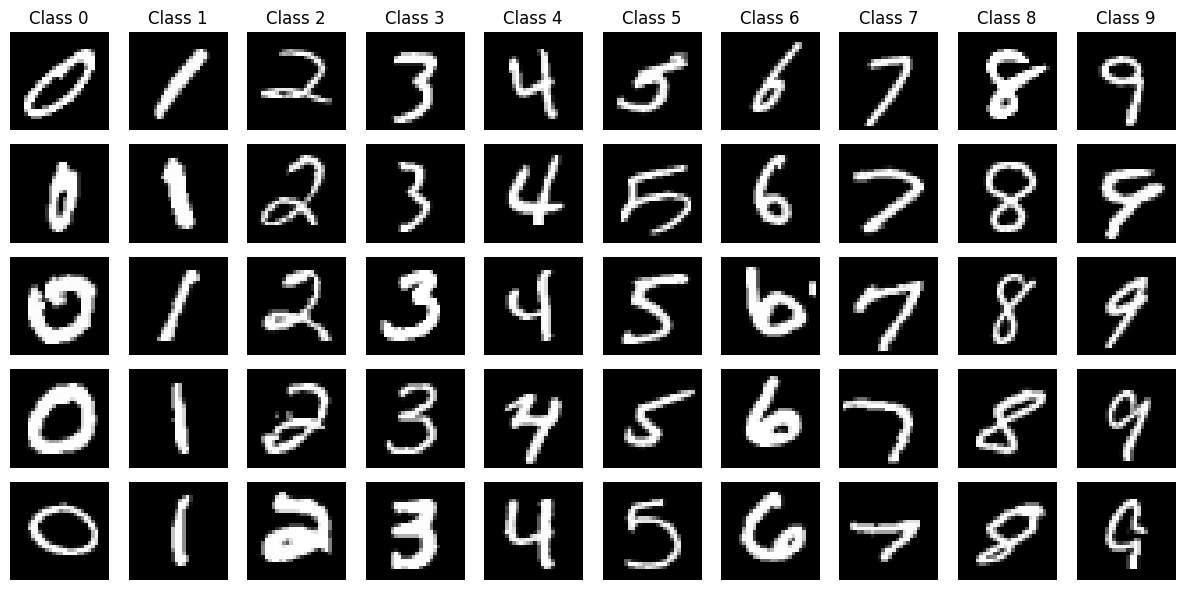

In [17]:
samples_per_class = 5
num_classes = 10

class_images = {i: [] for i in range(num_classes)}
classes_completed = 0

for image_tensor, label in trainset:
    if len(class_images[label]) < samples_per_class:
        class_images[label].append(image_tensor)
        if len(class_images[label]) == samples_per_class:
            classes_completed += 1

    if classes_completed == num_classes:
        break

fig, axes = plt.subplots(samples_per_class, num_classes, figsize=(12, 6))

for class_idx in range(num_classes):
    for sample_idx in range(samples_per_class):
        ax = axes[sample_idx, class_idx]

        img_tensor = class_images[class_idx][sample_idx]
        img_ready = img_tensor.squeeze().numpy()

        ax.imshow(img_ready, cmap='gray')
        ax.axis('off')

        if sample_idx == 0:
            ax.set_title(f'Class {class_idx}', fontsize=12)

plt.tight_layout()
plt.show()

## Networks

The package torch.nn defines a series of useful classes like linear networks layers, activation functions, loss functions etc.


Base Class: nn.Module

A Sequential container: nn.Sequential

A module list: nn.ModuleList

Different layers of neural network:
1.   Linear Layers
2.   Activations
3.   Colvolution Layers
4.   Pooling Layers
5.   Dropout Layers
6.   Normalization Layers
7.   Recurrent Layers
8.   Transformer Layers
9.   Vision Layers
10.  Shuffle Layers, etc.

A full list can be found [here](pytorch.org/docs/stable/nn.html). In case you need a certain network layer, check the documentation of the package first before writing the layer yourself as the package likely contains the code for it already.

Additionally to torch.nn, there is also torch.nn.functional. It contains functions that are used in network layers.

&emsp;&emsp;&emsp;&emsp;&emsp;`○ ○ ○ ○ ○ ○ ○ ○ ○ ○` (10 output features)

&emsp;&emsp;&emsp;&emsp;&emsp;`○ ○ ○ ○ ○ ○ ○ ○ ○ ○` (10 hidden features)

&emsp;&emsp;&emsp;&emsp;&emsp;`○ ○ ○ ○ ○ ○ ○ ○ ○ ○` (10 hidden features)

&emsp;&emsp;`○ ○ ○ ○ ○ ○ ○ ... ○ ○ ○ ○ ○ ○ ○` (128 hidden features)

`○ ○ ○ ○ ○ ○ ○ ○ ○ ... ○ ○ ○ ○ ○ ○ ○ ○ ○` (28 × 28 = 784 input features)

In [18]:
# defining a new neural network class called Classifier
class Classifier(nn.Module):
    def __init__(self):
        super(Classifier, self).__init__()
        self.d1 = nn.Linear(28 * 28, 128) #First fully connected layer- Input size: 28 × 28 = 784, Output size: 128
        self.d2 = nn.Linear(128, 10,bias=False) # Second fully connected layer, 128 hidden features → 10 output values
        self.relu=nn.ReLU()
        self.seq_container=nn.Sequential(nn.Linear(10, 10,bias=False),
                                         nn.ReLU(),
                                         nn.Linear(10, 10,bias=True))

    def forward(self, x):
       out = x.flatten(start_dim=1) # Flatten the input tensor to a 2D tensor (batch_size, 784)

       out = self.d1(out) # Pass the flattened input through the first fully connected layer
       out = self.relu(out)

       out = self.d2(out)
       out = self.relu(out)

       out = self.seq_container(out) # Pass the output through the sequential container

       return out

In [19]:
model = Classifier().to(device)
print(model)

Classifier(
  (d1): Linear(in_features=784, out_features=128, bias=True)
  (d2): Linear(in_features=128, out_features=10, bias=False)
  (relu): ReLU()
  (seq_container): Sequential(
    (0): Linear(in_features=10, out_features=10, bias=False)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)


In [20]:
# iterating over the training DataLoader.
for images, labels in trainloader:
    images = images.to(device)
    labels = labels.to(device)
    # images.shape represent - dimensions of the batch tensor
    #(batch_size, channels, height, width),
    # 32 images in the batch, 1 channel, each image is 28 × 28 pixels
    print("input size in a batch:", images.shape)
    out = model(images)
    # out.shape - shows the shape of the predictions, (batch_size, number_of_classes)
    print("output size in a batch:", out.shape)
    break


input size in a batch: torch.Size([128, 1, 28, 28])
output size in a batch: torch.Size([128, 10])


In [21]:
#param is a torch.Tensor that holds the actual parameter values (weights or biases)
#Parameter d1.weight, shape torch.Size([128, 784]) — meaning this is the weight matrix of layer d1 with 128 rows and 784 columns
for name, param in model.named_parameters():
    print(f"Parameter {name}, shape {param.shape}")

Parameter d1.weight, shape torch.Size([128, 784])
Parameter d1.bias, shape torch.Size([128])
Parameter d2.weight, shape torch.Size([10, 128])
Parameter seq_container.0.weight, shape torch.Size([10, 10])
Parameter seq_container.2.weight, shape torch.Size([10, 10])
Parameter seq_container.2.bias, shape torch.Size([10])


In [22]:
#structured summary of our neural network, architecture in a table format
# 128 features per input sample
# Input size = 28 × 28 = 784 , Output size = 128 , Parameters:
#Weights = 784 × 128 = 100,352
#Biases = 128, total number of parameters = 100,352 + 128 = 100,480
print(next(model.parameters()).device)
summary(model, (1, 28, 28))

cuda:0
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                  [-1, 128]         100,480
              ReLU-2                  [-1, 128]               0
            Linear-3                   [-1, 10]           1,280
              ReLU-4                   [-1, 10]               0
            Linear-5                   [-1, 10]             100
              ReLU-6                   [-1, 10]               0
            Linear-7                   [-1, 10]             110
Total params: 101,970
Trainable params: 101,970
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.39
Estimated Total Size (MB): 0.39
----------------------------------------------------------------


# Loss modules

We can calculate the loss for a batch by simply performing a few tensor operations as those are automatically added to the computation graph. For instance, for multi-class classification, we can use Cross Entropy (CE) which is defined as follows:

$$\mathcal{L}_{CE} = -\sum_i \sum_c y_{i,c} \log x_{i,c}$$

where $y$ are our one-hot encoded labels, and $x$ our predicted probabilities, both in the range of $[0,1]$. However, PyTorch already provides a list of predefined loss functions which we can use (see [here](https://pytorch.org/docs/stable/nn.html#loss-functions) for a full list). For instance, for CE, PyTorch has two related modules: `nn.NLLLoss()`, `nn.CrossEntropyLoss()`. While `nn.NLLLoss` expects the inputs $x$ to be log-probabilities, i.e. the output of a log-softmax, `nn.CrossEntropyLoss` combines a log-softmax layer and the negative log likelihood loss in a single class. This version is numerically more stable than using a plain Softmax followed by a negative log likelihood loss because of the logarithms applied in the loss function. Hence, it is advised to use loss functions applied on "logits" where possible (remember to not apply a softmax on the output of the model in this case!). For our model defined above, we therefore use the module `nn.CrossEntropyLoss`.

In [23]:
criterion = nn.CrossEntropyLoss()

#Training and Validating the Model

In [24]:
learning_rate = 1e-2
num_epochs = 25

In [25]:
#define a function named get_accuracy that takes three inputs: output: the model’s outputs for a batch, target: the ground-truth labels for the same batch, batch_size: the number of samples in the batch
def get_accuracy(output, target, batch_size):
    ''' Obtain accuracy for training round '''
    corrects = (torch.max(output, 1)[1].view(target.size()).data == target.data).sum() # finds how many predictions are correct
    accuracy = 100.0 * corrects/batch_size
    return accuracy.item()

In [26]:
from torch.utils.tensorboard import SummaryWriter
writer = SummaryWriter("runs/mnist_experiment")

# Training Loop
## train the model
for epoch in range(num_epochs):
    train_running_loss = 0.0
    val_loss = 0.0
    val_acc = 0.0

    # commence training
    model.train()

    # training step
    for i, (images, labels) in enumerate(trainloader):

        images = images.to(device)
        labels = labels.to(device)

        # forward
        predictions = model(images)

        loss = criterion(predictions, labels)

        # Calculate gradients
        loss.backward()

        # Temporarily turn off gradient tracking for the update step
        with torch.no_grad():
            for p in model.parameters():
                if p.grad is not None:
                    # Update the weights
                    p -= learning_rate * p.grad

                    # Manually zero the gradients for the next iteration
                    p.grad.zero_()

        train_running_loss += loss.detach().item()


    model.eval()
    with torch.no_grad():
        for images, labels in valloader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            val_acc += get_accuracy(outputs, labels, BATCH_SIZE)

    train_running_loss /= len(trainloader)
    val_loss /= len(valloader)
    val_acc /= len(valloader)

    # Log the losses
    # logging two scalar values to TensorBoard: training loss, validation loss
    writer.add_scalars('Loss', {'train': train_running_loss, 'val': val_loss}, epoch)

    # Log the accuracy
    writer.add_scalars('Accuracy', {'val': val_acc}, epoch)
    print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_running_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

writer.flush()

%load_ext tensorboard
# Launching TensorBoard
%tensorboard --logdir=runs

Epoch 1/25, Train Loss: 2.3009, Val Loss: 2.2831, Val Acc: 16.4811
Epoch 2/25, Train Loss: 2.2447, Val Loss: 2.1877, Val Acc: 29.4548
Epoch 3/25, Train Loss: 2.0212, Val Loss: 1.7631, Val Acc: 41.1818
Epoch 4/25, Train Loss: 1.4069, Val Loss: 1.1042, Val Acc: 66.0406
Epoch 5/25, Train Loss: 0.9214, Val Loss: 0.8055, Val Acc: 73.2962
Epoch 6/25, Train Loss: 0.7274, Val Loss: 0.6801, Val Acc: 78.0834
Epoch 7/25, Train Loss: 0.6275, Val Loss: 0.6011, Val Acc: 81.5991
Epoch 8/25, Train Loss: 0.5624, Val Loss: 0.5430, Val Acc: 83.6602
Epoch 9/25, Train Loss: 0.5142, Val Loss: 0.5026, Val Acc: 85.1729
Epoch 10/25, Train Loss: 0.4745, Val Loss: 0.4633, Val Acc: 86.3697
Epoch 11/25, Train Loss: 0.4401, Val Loss: 0.4354, Val Acc: 87.2424
Epoch 12/25, Train Loss: 0.4119, Val Loss: 0.4075, Val Acc: 88.1732
Epoch 13/25, Train Loss: 0.3879, Val Loss: 0.3837, Val Acc: 88.7217
Epoch 14/25, Train Loss: 0.3674, Val Loss: 0.3667, Val Acc: 89.0209
Epoch 15/25, Train Loss: 0.3492, Val Loss: 0.3491, Val Ac

<IPython.core.display.Javascript object>

In [27]:
test_acc = 0.0
true_labels = [] # empty Python list that will store the ground-truth labels for all test samples
predictions = [] # empty list that will store the model’s predicted class labels for all test samples
for i, (images, labels) in enumerate(testloader, 0):
   # move the image tensors and label tensors to the same device as the model
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images) # forward pass
    # true_labels → list of all true labels in the test set, predictions → list of all predicted labels
    true_labels.extend(labels.cpu().numpy().astype(int))
    predictions.extend(np.argmax(outputs.detach().cpu().numpy(), axis=1))

# Calculate accuracy, precision, recall
accuracy = accuracy_score(true_labels, predictions)
precision = precision_score(true_labels, predictions, average='weighted')
recall = recall_score(true_labels, predictions, average='weighted')
# confusion matrix shows: actual classes vs predicted classes, exactly where the model is making mistakes
# Rows = True (actual) classes, Columns = Predicted classes, diagonal elements are where: true class = predicted class
conf_matrix = confusion_matrix(true_labels, predictions)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print("Confusion Matrix:\n",conf_matrix)

Accuracy: 0.9386
Precision: 0.9386
Recall: 0.9386
Confusion Matrix:
 [[ 964    0    0    0    2    3    4    3    4    0]
 [   0 1117    2    3    0    1    2    1    8    1]
 [  10    1  974    7    7    3    7    6   15    2]
 [   1    2   28  939    0   11    0    8   17    4]
 [   3    0   11    0  918    0    5    2    5   38]
 [  10    1    5   29    5  803   11    1   19    8]
 [   7    3    5    0   12   13  915    0    3    0]
 [   1    9   22    4    6    1    0  962    1   22]
 [   6    7   10   20    9   17   12    5  877   11]
 [   7    6    1    8   28    2    1   23   16  917]]


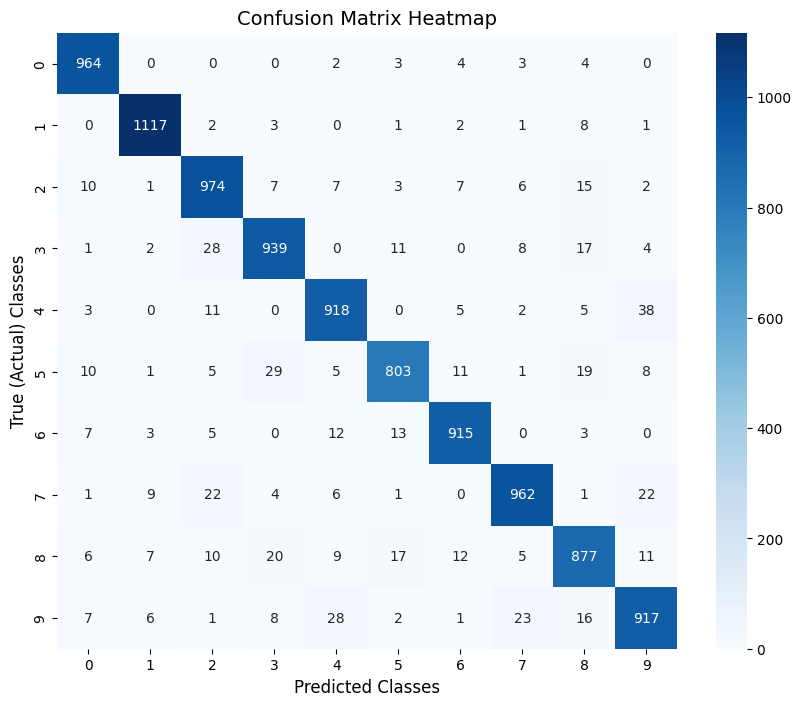

In [28]:
# Set the size of the figure
plt.figure(figsize=(10, 8))

# Create a heatmap using seaborn
# annot=True puts the numbers inside the squares
# fmt='d' ensures the numbers are formatted as integers
# cmap='Blues' sets the color scheme (darker blue = higher numbers)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')

# Add labels and title for clarity
plt.xlabel('Predicted Classes', fontsize=12)
plt.ylabel('True (Actual) Classes', fontsize=12)
plt.title('Confusion Matrix Heatmap', fontsize=14)

# Display the plot
plt.show()

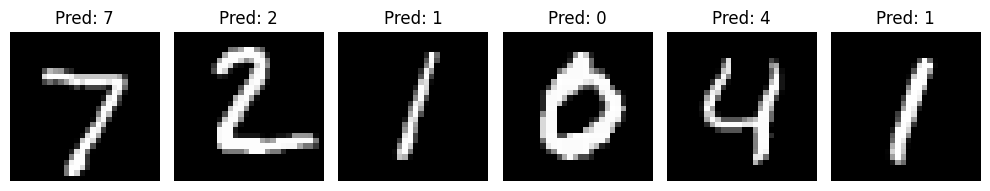

Predictions as a single number: 721041


In [29]:
import matplotlib.pyplot as plt
import torch
import numpy as np

# Accumulate exactly 6 samples from the testloader
collected_images = []
collected_labels = []
num_needed = 6
current_count = 0

for images, labels in testloader:
    collected_images.append(images)
    collected_labels.append(labels)
    current_count += images.size(0)

    # Stop gathering once we have at least 6 samples
    if current_count >= num_needed:
        break

# Concatenate all gathered batches into a single tensor
images_concat = torch.cat(collected_images, dim=0)
labels_concat = torch.cat(collected_labels, dim=0)

# Slice out exactly the first 6 samples and move to device
images_6 = images_concat[:num_needed].to(device)
labels_6 = labels_concat[:num_needed].to(device)

# Forward pass to get predictions
with torch.no_grad():
    outputs_6 = model(images_6)

# Get the predicted classes using torch.max along axis 1
_, preds_tensor = torch.max(outputs_6, 1)
preds_6 = preds_tensor.cpu().numpy()

# Plot the 6 images horizontally
fig, axes = plt.subplots(1, num_needed, figsize=(10, 2))

for i in range(num_needed):
    # Move image back to CPU and convert to numpy
    img = images_6[i].cpu().numpy()

    # Adjust axes for Matplotlib (H, W, C) or Grayscale
    if img.shape[0] == 3: # RGB
        img = np.transpose(img, (1, 2, 0))
        img = np.clip(img, 0, 1) # Clip to [0, 1] just in case of minor float drift
    elif img.shape[0] == 1: # Grayscale
        img = img.squeeze(0)

    axes[i].imshow(img, cmap='gray' if len(img.shape) == 2 else None)
    axes[i].set_title(f"Pred: {preds_6[i]}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Print the prediction array as a single number
# Converts the array (e.g., [1, 0, 2, 4, 1, 3]) to a single integer (102413)
single_number_pred = int("".join(map(str, preds_6)))
print(f"Predictions as a single number: {single_number_pred}")

In [30]:
# defining an adjustable neural network class called AdjustableClassifier
class AdjustableClassifier(nn.Module):
    def __init__(self, num_ind_layers=4, num_features_per_layer=128):
        super(AdjustableClassifier, self).__init__()
        # number of individual layers
        self.num_ind_layers = num_ind_layers

        # list of all layers with empty initialization
        self.linear_layers = nn.ModuleList()

        # adding layers to the list
        for idx in range(self.num_ind_layers):
            if idx == 0:
                # first layer, takes 28 * 28 = 784 input features
                self.linear_layers.append(nn.Linear(28 * 28, num_features_per_layer))
            elif idx != (self.num_ind_layers - 1):
                # all layers except first and last layers
                self.linear_layers.append(nn.Linear(num_features_per_layer, num_features_per_layer))
            else:
                # last layer, produces 10 output features
                self.linear_layers.append(nn.Linear(num_features_per_layer, 10))

        # activation function
        self.relu = nn.ReLU()

    def forward(self, x):
        # converting 2D image into 1D array
        out = x.flatten(start_dim=1)

        # processing the input through all layers, with activation (except last layer which is without activation)
        for layer_idx in range(self.num_ind_layers):
            out = self.linear_layers[layer_idx](out)
            if layer_idx != (self.num_ind_layers - 1):
                out = self.relu(out)

        return out

In [32]:
def train_model(model, num_epochs=25):
    for epoch in range(num_epochs):
        train_running_loss = 0.0
        val_loss = 0.0
        val_acc = 0.0

        # model in training mode
        model.train()

        for i, (images, labels) in enumerate(trainloader):
            # changing the device (CPU or GPU) for the inputs and targets
            images = images.to(device)
            labels = labels.to(device)

            # model output predictions
            predictions = model(images)

            # loss calculation
            loss = criterion(predictions, labels)

            # calculating the gradients for each parameter
            loss.backward()

            with torch.no_grad():  # no further gradient tracking
                for p in model.parameters():  # for all the parameters
                    if p.grad is not None:
                        p -= learning_rate * p.grad  # update parameters

                        p.grad.zero_()  # zero the gradients to prevent erroneous gradient addition

            train_running_loss += loss.detach().item()  # add loss of batch to the total loss count for the epoch

        # model in evaluation mode
        model.eval()
        with torch.no_grad():
            for images, labels in valloader:
                # changing the device (CPU or GPU) for the inputs and targets
                images = images.to(device)
                labels = labels.to(device)

                # model output predictions
                outputs = model(images)

                # loss calculation
                loss = criterion(outputs, labels)

                # calculate validation loss and accuracy
                val_loss += loss.item()
                val_acc += get_accuracy(outputs, labels, BATCH_SIZE)

        # calculate mean losses and accuracy per sample
        train_running_loss /= len(trainloader)
        val_loss /= len(valloader)
        val_acc /= len(valloader)

        # print the results for the first and last epochs
        if (epoch == 0) or (epoch == (num_epochs - 1)):
            print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_running_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

    # testing

    test_acc = 0.0
    true_labels = []
    predictions = []
    for i, (images, labels) in enumerate(testloader, 0):
        # changing the device (CPU or GPU) for the inputs and targets
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images) # forward pass
        true_labels.extend(labels.cpu().numpy().astype(int))
        predictions.extend(np.argmax(outputs.detach().cpu().numpy(), axis=1))

    # calculating performance metrics
    accuracy = accuracy_score(true_labels, predictions)
    precision = precision_score(true_labels, predictions, average='weighted')
    recall = recall_score(true_labels, predictions, average='weighted')
    conf_matrix = confusion_matrix(true_labels, predictions)

    return [accuracy, precision, recall, conf_matrix]

In [33]:
num_epochs_to_train = 10

# initializing lists to store performance metrics values for multiple models
accuracy_values = []
precision_values = []
recall_values = []
conf_matrices = []

for num_ind_layers in [2, 3, 4]:  # number of individual layers in the model
  for num_features_per_layer in [4, 8, 12]:  # number of features per layer in the model
    print("\n")
    print(f"Number of individual layers: {num_ind_layers}")
    print(f"Number of features per layer: {num_features_per_layer}")

    # initialize adjustable model
    current_model = AdjustableClassifier(num_ind_layers, num_features_per_layer).to(device)

    # train and store performance metrics in "results" variable for the model
    results = train_model(current_model, num_epochs=num_epochs_to_train)

    # include the results in the lists that store metrics for all the models
    accuracy_values.append(results[0])
    precision_values.append(results[1])
    recall_values.append(results[2])
    conf_matrices.append(results[3])

    print(f"Accuracy: {accuracy_values[-1]:.4f}")
    print(f"Precision: {precision_values[-1]:.4f}")
    print(f"Recall: {recall_values[-1]:.4f}")



Number of individual layers: 2
Number of features per layer: 4
Epoch 1/10, Train Loss: 2.0926, Val Loss: 1.8973, Val Acc: 31.2999
Epoch 10/10, Train Loss: 0.6834, Val Loss: 0.6848, Val Acc: 78.9644
Accuracy: 0.8023
Precision: 0.8023
Recall: 0.8023


Number of individual layers: 2
Number of features per layer: 8
Epoch 1/10, Train Loss: 1.9780, Val Loss: 1.6064, Val Acc: 65.4422
Epoch 10/10, Train Loss: 0.3927, Val Loss: 0.3935, Val Acc: 88.4475
Accuracy: 0.8948
Precision: 0.8945
Recall: 0.8948


Number of individual layers: 2
Number of features per layer: 12
Epoch 1/10, Train Loss: 1.9468, Val Loss: 1.5588, Val Acc: 56.3664
Epoch 10/10, Train Loss: 0.3891, Val Loss: 0.3847, Val Acc: 88.9212
Accuracy: 0.8962
Precision: 0.8961
Recall: 0.8962


Number of individual layers: 3
Number of features per layer: 4
Epoch 1/10, Train Loss: 2.3132, Val Loss: 2.2763, Val Acc: 9.8072
Epoch 10/10, Train Loss: 0.9744, Val Loss: 0.9506, Val Acc: 68.7500
Accuracy: 0.6937
Precision: 0.6924
Recall: 0.6937


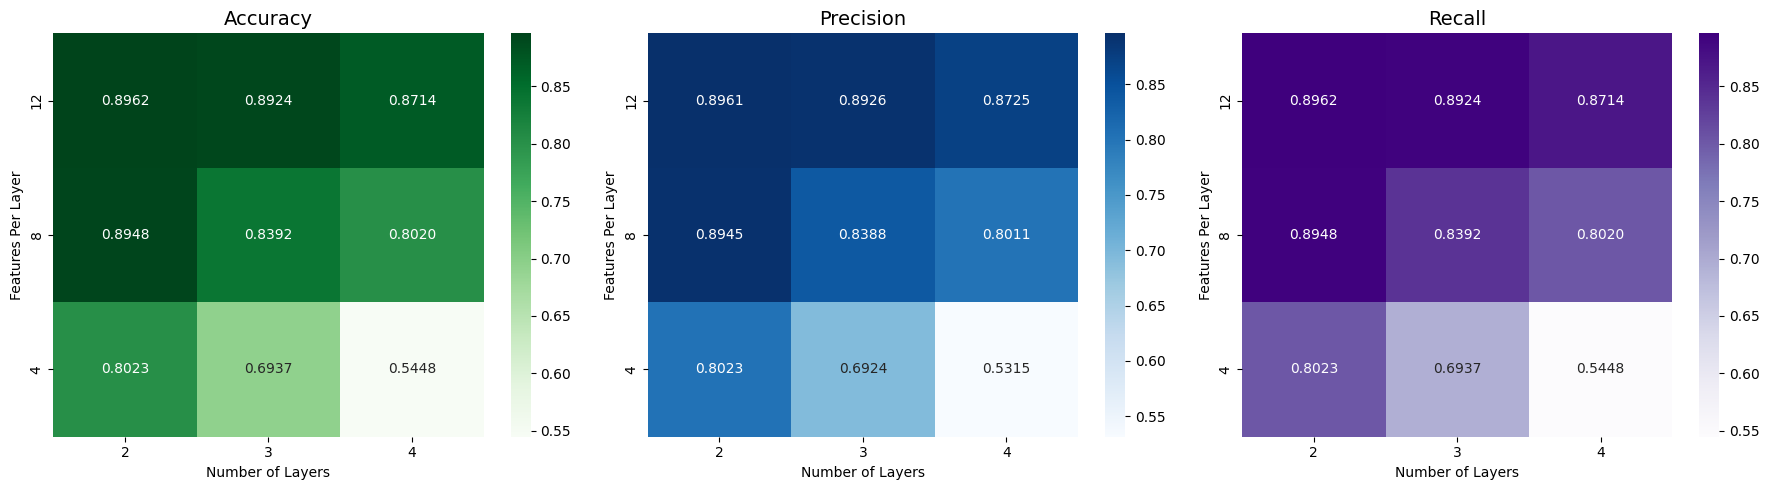

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define grid parameters
layers_list = [2, 3, 4]
features_list = [4, 8, 12]

# Reshape and transpose the lists (Rows = Features, Columns = Layers)
acc_2d = np.array(accuracy_values).reshape(len(layers_list), len(features_list)).T
prec_2d = np.array(precision_values).reshape(len(layers_list), len(features_list)).T
rec_2d = np.array(recall_values).reshape(len(layers_list), len(features_list)).T

# Set up a 1x3 horizontal grid of plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Accuracy Heatmap
sns.heatmap(acc_2d, annot=True, fmt=".4f", cmap="Greens",
            xticklabels=layers_list, yticklabels=features_list, ax=axes[0])
axes[0].set_title("Accuracy", fontsize=14)
axes[0].set_xlabel("Number of Layers")
axes[0].set_ylabel("Features Per Layer")
axes[0].invert_yaxis() # Flips Y-axis so smaller numbers are at the bottom

# Precision Heatmap
sns.heatmap(prec_2d, annot=True, fmt=".4f", cmap="Blues",
            xticklabels=layers_list, yticklabels=features_list, ax=axes[1])
axes[1].set_title("Precision", fontsize=14)
axes[1].set_xlabel("Number of Layers")
axes[1].set_ylabel("Features Per Layer")
axes[1].invert_yaxis()

# Recall Heatmap
sns.heatmap(rec_2d, annot=True, fmt=".4f", cmap="Purples",
            xticklabels=layers_list, yticklabels=features_list, ax=axes[2])
axes[2].set_title("Recall", fontsize=14)
axes[2].set_xlabel("Number of Layers")
axes[2].set_ylabel("Features Per Layer")
axes[2].invert_yaxis()

# Adjust spacing between plots so labels don't overlap
plt.tight_layout()
plt.show()

#Sources:
https://pytorch.org/docs/stable/index.html

Other Interesting Notebooks and Blogs:

1. https://github.com/dair-ai/pytorch_notebooks/blob/master/A_Gentle_Introduction_to_PyTorch_1_2.ipynb

2. https://colab.research.google.com/github/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial2/Introduction_to_PyTorch.ipynb

3. https://github.com/mrdbourke/pytorch-deep-learning/blob/main/extras/pytorch_2_intro.ipynb

4. https://github.com/Paperspace/PyTorch-101-Tutorial-Series

5. https://blog.paperspace.com/pytorch-101-understanding-graphs-and-automatic-differentiation/

6. https://colab.research.google.com/github/dvgodoy/PyTorch101_ODSC_London2019/blob/master/PyTorch101_Colab.ipynb#scrollTo=KeV7KOyBUi2S